# Exact sampling: adaptive rejection and learned proposals

MCMC returns a correlated chain that is only asymptotically exact. Rejection
sampling returns **independent, exact** draws, at the price of needing an
envelope: a proposal $q$ and a constant $M$ with $p(x) \le M q(x)$. Draw
$x \sim q$ and accept with probability $p(x) / (M q(x))$; the accepted draws
are distributed exactly as $p$.

In probjax the exact samplers are kernels like any other, so `run`, `warmup`,
adaptors and `jax.vmap` work unchanged. Every step returns one exact draw:

- `ars` builds its envelope from tangents of a log-concave density and
  tightens it inside the state as it samples.
- `rejection` takes any `Density` as $q$. The bound $\log M$ is a parameter,
  learned by `bound_adaptor`, and a flow proposal can be trained on the
  accepted draws with `fit_adaptor`.

This notebook runs on CPU in well under a minute.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax
from flax import nnx

jax.config.update("jax_platform_name", "cpu")

from probjax.inference import (
    Density, ars, bound_adaptor, compose_adaptors, fit_adaptor, maximum_likelihood,
    rejection, run, warmup,
)
from probjax.inference.neural import density
from probjax.inference.rejection import univariate
from probjax.nn import maf

## 1. Adaptive rejection sampling

The posterior of a Poisson log-rate $\theta$ with a $\mathcal N(0, 2^2)$ prior
is log-concave:
$\log p(\theta \mid y) = \theta \sum_i y_i - n e^{\theta} - \theta^2 / 8 + c$.
ARS needs only the log density and a starting point. The envelope starts from
three tangents; whenever a draw falls between the squeeze (the chords) and
the envelope, the target is evaluated there and a tangent is added.

In [2]:
counts = jnp.array([3, 7, 4, 6, 5, 2, 8, 5])


def log_rate_posterior(theta):
    return theta * counts.sum() - counts.size * jnp.exp(theta) - theta**2 / 8


kernel = ars(log_rate_posterior)
state = kernel.init(jax.random.key(0), 0.0)
initial_envelope = state.envelope

start = time.perf_counter()
result = run(jax.random.key(1), kernel, state, None, 5000,
             collect=("position", "num_proposals", "num_evals"))
print(f"5000 exact draws in {time.perf_counter() - start:.2f}s")
print(f"target evaluations: {int(result.trace['num_evals'].sum())}, "
      f"tangent points: {int(result.state.envelope.num_points)}")
print(f"envelope draws per accepted draw: {result.trace['num_proposals'].mean():.3f}")

5000 exact draws in 0.21s
target evaluations: 45, tangent points: 48
envelope draws per accepted draw: 1.004


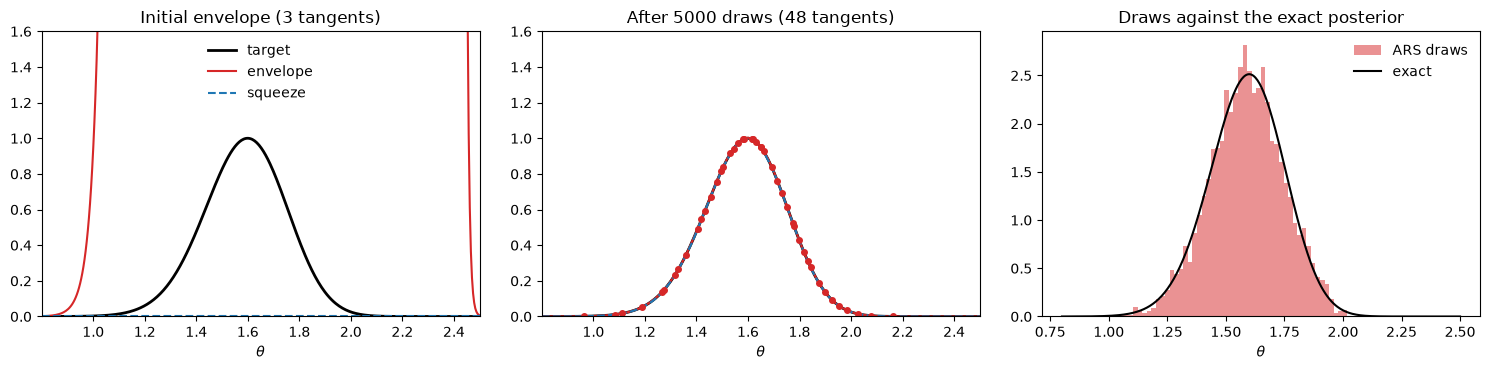

In [3]:
grid = jnp.linspace(0.8, 2.5, 400)
log_target = log_rate_posterior(grid)
shift = log_target.max()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, env, title in [
    (axes[0], initial_envelope, "Initial envelope (3 tangents)"),
    (axes[1], result.state.envelope, f"After 5000 draws ({int(result.state.envelope.num_points)} tangents)"),
]:
    upper = jax.vmap(lambda x: univariate.upper_hull(env, x))(grid)
    lower = jax.vmap(lambda x: univariate.squeeze(env, x))(grid)
    ax.plot(grid, jnp.exp(log_target - shift), "k", lw=2, label="target")
    ax.plot(grid, jnp.exp(upper - shift), color="tab:red", label="envelope")
    ax.plot(grid, jnp.exp(lower - shift), color="tab:blue", ls="--", label="squeeze")
    points = env.x[: int(env.num_points)]
    ax.plot(points, jnp.exp(log_rate_posterior(points) - shift), "o", color="tab:red", ms=4)
    ax.set(xlim=(grid[0], grid[-1]), ylim=(0, 1.6), xlabel=r"$\theta$", title=title)
axes[0].legend(frameon=False)

density_on_grid = jnp.exp(log_target - jax.scipy.special.logsumexp(log_target)) / (grid[1] - grid[0])
axes[2].hist(result.trace["position"], bins=60, density=True, color="tab:red", alpha=0.5, label="ARS draws")
axes[2].plot(grid, density_on_grid, "k", lw=1.5, label="exact")
axes[2].set(xlabel=r"$\theta$", title="Draws against the exact posterior")
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

The envelope starts loose, so early draws are often rejected and each
rejection teaches it a tangent. After a few dozen evaluations it hugs the
target, the squeeze accepts almost every draw without touching the target,
and the remaining thousands of draws cost essentially nothing. Refining the
envelope never affects exactness: every accepted draw is exact whatever the
envelope looks like at the time.

## 2. Rejection sampling with a learned bound

For a multivariate target, `rejection` takes any proposal with heavier
tails. The target here is a banana,
$x_1 \sim \mathcal N(0, 2^2)$, $x_2 \mid x_1 \sim \mathcal N(x_1^2/2 - 2, 0.5^2)$,
and the proposal a broad Gaussian. $\log M$ is unknown, so the kernel starts
with $\log M = -\infty$ and its default adaptation, `bound_adaptor`, raises it
to the largest $\log p - \log q$ seen during warmup. Each step's info reports
the largest ratio among its proposals, so a bound that is still too low shows
up as `max_log_ratio > log_bound`.

In [4]:
def banana(x):
    return -0.5 * (x[0] ** 2 / 4 + (x[1] - 0.5 * x[0] ** 2 + 2) ** 2 / 0.25)


broad = Density(
    sample=lambda key, scale: scale * jax.random.normal(key, (2,)),
    logpdf=lambda x, scale: jax.scipy.stats.norm.logpdf(x, 0.0, scale).sum(),
)
kernel = rejection(banana, proposal=broad)
state = kernel.init(jax.random.key(0), jnp.zeros(2))
params = kernel.init_params(state, 4.0)

tuned = warmup(jax.random.key(1), kernel, state, params, 2000)
gaussian_draws = run(jax.random.key(2), kernel, tuned.state, tuned.params, 5000,
                     collect=("position", "num_proposals", "max_log_ratio")).trace


def report(name, trace, log_bound):
    violations = int((trace["max_log_ratio"] > log_bound).sum())
    lag_one = jnp.corrcoef(trace["position"][:-1, 0], trace["position"][1:, 0])[0, 1]
    print(f"{name:>16}: log M = {float(log_bound):5.2f}, proposals per draw = "
          f"{trace['num_proposals'].mean():5.1f}, steps exceeding the bound = {violations}, "
          f"lag-1 autocorrelation = {lag_one:+.3f}")


gaussian_bound = tuned.params.log_bound
report("Gaussian q", gaussian_draws, gaussian_bound)

      Gaussian q: log M =  7.11, proposals per draw = 197.3, steps exceeding the bound = 2, lag-1 autocorrelation = +0.021


The draws are independent: the lag-1 autocorrelation is zero up to noise,
where an MCMC chain would show strong correlation. The cost moves into the
number of proposals per draw, which is $M$ times the ratio of normalising
constants: a broad Gaussian wastes most proposals in the empty space around
the banana. A small number of steps exceeding the bound means warmup saw
nearly, but not exactly, the largest ratio. Those draws are slightly
over-represented, so warm up longer or pass `bound_adaptor(margin=...)` when
that matters.

## 3. A learned flow proposal

A proposal that matches the target needs far fewer proposals per draw. The
accepted draws are exact target samples, so they are exactly the right data
for training a flow by maximum likelihood. `fit_adaptor(field="proposal")`
does that inside the scan, composed with `bound_adaptor` so the bound keeps
up. The flow starts broad (standardization scale 4).

In [5]:
flow = maf(2, 3, rngs=nnx.Rngs(0))
flow.set_standardization(jnp.zeros(2), 4.0 * jnp.ones(2))
proposal, proposal_params = density(flow)

kernel = rejection(banana, proposal=proposal)
state = kernel.init(jax.random.key(0), jnp.zeros(2))
policy = compose_adaptors(
    proposal=fit_adaptor(maximum_likelihood(proposal), optax.adam(3e-3), field="proposal"),
    bound=bound_adaptor(),
)

start = time.perf_counter()
trained = run(jax.random.key(1), kernel, state, kernel.init_params(state, proposal_params), 3000,
              adaptor=policy, collect=("num_proposals",))
print(f"training: {time.perf_counter() - start:.1f}s, log M after training = {float(trained.params.log_bound):.2f}")

training: 0.5s, log M after training = 6.13


The bound only ever grows, so after training it still reflects the poor early
proposals and is far too loose for the trained flow: the number of proposals
per draw stays high (left panel below). The remedy is a second, short phase:
keep the trained flow fixed and learn the bound afresh.

In [6]:
fresh = trained.params._replace(log_bound=jnp.asarray(-jnp.inf))
tuned = warmup(jax.random.key(2), kernel, trained.state, fresh, 2000)
flow_draws = run(jax.random.key(3), kernel, tuned.state, tuned.params, 5000,
                 collect=("position", "num_proposals", "max_log_ratio")).trace

report("Gaussian q", gaussian_draws, gaussian_bound)
report("trained flow q", flow_draws, tuned.params.log_bound)

      Gaussian q: log M =  7.11, proposals per draw = 197.3, steps exceeding the bound = 2, lag-1 autocorrelation = +0.021
  trained flow q: log M =  3.30, proposals per draw =   4.4, steps exceeding the bound = 8, lag-1 autocorrelation = -0.026


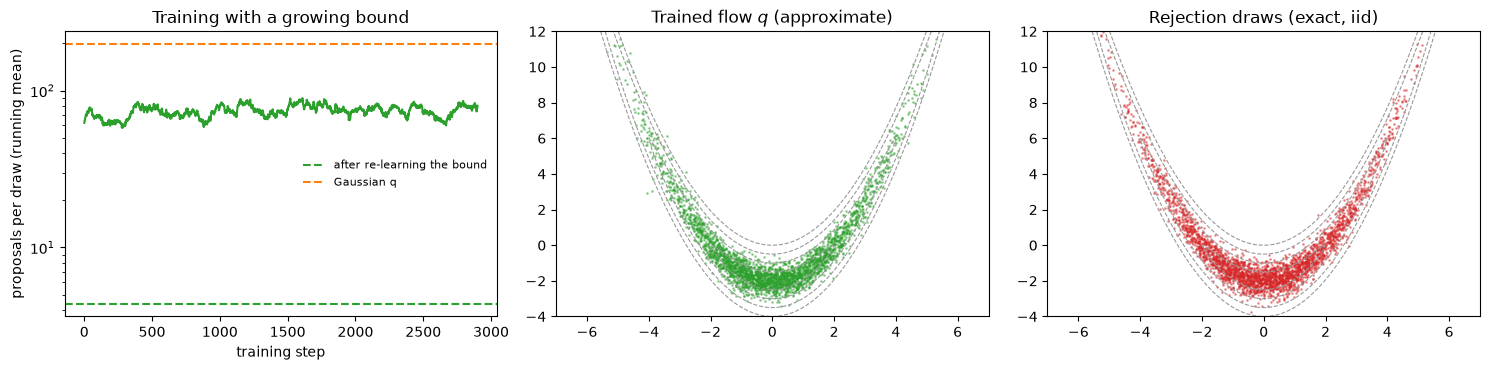

In [7]:
xs, ys = jnp.meshgrid(jnp.linspace(-7, 7, 200), jnp.linspace(-4, 12, 200))
log_banana = jax.vmap(jax.vmap(lambda a, b: banana(jnp.array([a, b]))))(xs, ys)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
window = 100
axes[0].plot(jnp.convolve(trained.trace["num_proposals"], jnp.ones(window) / window, mode="valid"),
             color="tab:green")
axes[0].axhline(flow_draws["num_proposals"].mean(), color="tab:green", ls="--", label="after re-learning the bound")
axes[0].axhline(gaussian_draws["num_proposals"].mean(), color="tab:orange", ls="--", label="Gaussian q")
axes[0].set(xlabel="training step", ylabel="proposals per draw (running mean)", yscale="log",
            title="Training with a growing bound")
axes[0].legend(frameon=False, fontsize=8)

flow_samples = jax.vmap(proposal.sample, (0, None))(jax.random.split(jax.random.key(4), 3000), tuned.params.proposal)
for ax, points, color, title in [
    (axes[1], flow_samples, "tab:green", "Trained flow $q$ (approximate)"),
    (axes[2], flow_draws["position"][:3000], "tab:red", "Rejection draws (exact, iid)"),
]:
    ax.contour(xs, ys, log_banana, levels=[-8, -4.5, -2, -0.5], colors="0.6", linewidths=0.8)
    ax.scatter(*points.T, s=1, alpha=0.4, color=color, rasterized=True)
    ax.set(xlim=(-7, 7), ylim=(-4, 12), title=title)
plt.tight_layout()
plt.show()

With the bound re-learned, the trained flow needs a fraction of the proposals
the broad Gaussian needs, and every accepted draw is still exact: the flow's
own mistakes (its samples are visibly off in the tips of the banana) are
corrected by the accept step, not inherited.

## When to use what

| Situation | Use |
| --- | --- |
| Univariate, log-concave (conditionals in a Gibbs sampler, GLM posteriors per coordinate) | `ars`: exact, and nearly free once the envelope is tight |
| Univariate, not log-concave | `arms` (an MCMC kernel on the same envelope) |
| Low dimension, a proposal with heavier tails is available | `rejection` with `bound_adaptor` warmup |
| The proposal is poor | Train a flow with `fit_adaptor(field="proposal")`, then re-learn the bound with the flow fixed |
| High dimension | MCMC: the proposals needed per draw grow exponentially with dimension |

Caveats:

- **The bound has to be a bound.** Draws are exact only where
  $\log p - \log q \le \log M$. `bound_adaptor` learns $\log M$ from what it
  sees, so check `max_log_ratio` against `log_bound` on the draws you keep,
  and give the proposal heavier tails than the target, or no finite bound
  exists at all.
- **Freeze adaptation for the draws you report**, as with MCMC: a bound that
  is still growing over-represents the regions where it was too low.